# Model Training

In this notebook, we train machine learning models to predict customer churn.

We begin with Logistic Regression as a baseline model and then compare its performance with more complex algorithms.

The main objective is to identify customers who are likely to churn while evaluating model performance using appropriate classification metrics.

In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Load dataset
file_path=Path.cwd().parent / "data" / "raw" / "Telco_customer_churn.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name = "Telco_Churn"
)

data = df.copy()

# Define target and features
y = data["Churn Value"]

columns_to_drop = [
    "CustomerID", "Churn Label", "Churn Value",
    "Churn Reason", "Churn Score", "CLTV",
    "Count", "Country", "State"
]

X = data.drop(columns=columns_to_drop)

# Correct numerical data type
X["Total Charges"] = pd.to_numeric(
    X["Total Charges"].astype(str).str.strip(),
    errors="coerce"
)

# Split features
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (5634, 24)
Testing: (1409, 24)


## 3. Baseline Model - Logistic Regression

Logistic Regression is used as the baseline classification model.

It estimates the probability of customer churn based on the input features.

A preprocessing pipeline is integrated with the model to handle missing values, feature scaling, and categorical encoding.

The initial model is trained without class balancing techniques to establish a baseline performance.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Create complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Logistic Regression Baseline

A Logistic Regression classifier was trained as the baseline model.

Preprocessing steps were integrated into a single Pipeline to ensure consistent transformations and prevent data leakage.

No class balancing technique was applied at this stage. This provides a baseline for comparison with later experiments.

## 4. Model Prediction

The trained Logistic Regression model is used to predict customer churn on the unseen test dataset.

Both predicted class labels and churn probabilities are generated for further evaluation.

In [4]:
# Predict customer churn
y_pred = logistic_model.predict(X_test)

# Predict churn probabilities
y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 churn probabilities:")
print(y_pred_proba[:10].round(3))

First 10 predictions:
[0 1 0 0 0 1 1 0 0 0]

First 10 churn probabilities:
[0.056 0.792 0.059 0.353 0.01  0.576 0.581 0.06  0.001 0.376]


## 5. Model Evaluation

In this section, we evaluate the Logistic Regression model using multiple classification metrics.

Accuracy alone is not sufficient because the dataset is imbalanced.

We therefore examine Precision, Recall, F1-score, and ROC-AUC to obtain a more complete understanding of model performance.

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_pred_proba)
}

metrics_df = pd.DataFrame(
    results.items(),
    columns=["Metric", "Score"]
)

display(metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7885
1,Precision,0.6173
2,Recall,0.5348
3,F1-Score,0.5731
4,ROC-AUC,0.8336


In [ ]:
### Logistic Regression Results

The baseline Logistic Regression model achieved an accuracy of 78.85% and a ROC-AUC score of 0.8336.

The model achieved a recall of 53.48%, meaning that it identified approximately half of the customers who actually churned.

Although the model demonstrates good overall discrimination, its recall and F1-score indicate room for improvement.

Further experiments with more advanced classification algorithms will be conducted to improve churn detection performance.

## 6. Confusion Matrix

The confusion matrix provides a detailed view of the model's classification performance.

It shows the number of correctly and incorrectly predicted churn and non-churn customers.

In [6]:
cm = confusion_matrix(y_test, y_pred)

cm_df = pd.DataFrame(
    cm,
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
)

display(cm_df)

,Predicted No Churn,Predicted Churn
Actual No Churn,911,124
Actual Churn,174,200


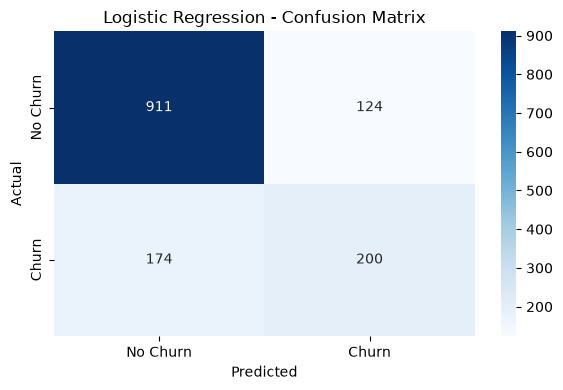

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
### Confusion Matrix Analysis

The confusion matrix shows that the Logistic Regression model correctly identified 200 churn customers and 911 non-churn customers.

However, it failed to identify 174 actual churn customers (False Negatives).

This indicates that the model still misses a considerable proportion of customers who are likely to leave.

Improving churn detection, particularly Recall, will be an important objective in the next modeling experiments.

## 7. Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

It can capture non-linear relationships and complex patterns in customer data.

In this section, we train a Random Forest model and evaluate whether it improves churn prediction performance compared to Logistic Regression.

In [10]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


## 8. Random Forest Predictions

We use the trained Random Forest model to predict churn labels and churn probabilities on the test dataset.

In [11]:
rf_pred = rf_model.predict(X_test)
rf_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("First 10 predictions:", rf_pred[:10])
print("First 10 churn probabilities:", rf_pred_proba[:10].round(3))

First 10 predictions: [0 1 0 1 0 1 1 0 0 1]
First 10 churn probabilities: [0.035 0.755 0.095 0.51  0.04  0.76  0.51  0.175 0.005 0.59 ]


## 9. Random Forest Evaluation

We evaluate the Random Forest model using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

These metrics allow us to compare its performance with the Logistic Regression baseline.

In [12]:
rf_results = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred),
    "Recall": recall_score(y_test, rf_pred),
    "F1-Score": f1_score(y_test, rf_pred),
    "ROC-AUC": roc_auc_score(y_test, rf_pred_proba)
}

rf_metrics_df = pd.DataFrame(
    rf_results.items(),
    columns=["Metric", "Score"]
)

display(rf_metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7800
1,Precision,0.5717
2,Recall,0.6818
3,F1-Score,0.6220
4,ROC-AUC,0.8438


### Random Forest Results

The Random Forest model achieved an accuracy of 78.00% and a ROC-AUC score of 0.8438.

Compared to Logistic Regression, Random Forest improved Recall from 53.48% to 68.18% and F1-score from 57.31% to 62.20%.

Although Precision and Accuracy decreased slightly, the model identified a larger proportion of actual churn customers.

This makes Random Forest a promising candidate for churn prediction, especially when identifying potential customer losses is a priority.

## 10. XGBoost Classifier

XGBoost is a gradient boosting algorithm that builds an ensemble of decision trees sequentially.

Each new tree attempts to correct errors made by previous trees.

In this section, we train an XGBoost model and compare its performance with Logistic Regression and Random Forest.

In [14]:
from xgboost import XGBClassifier

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [ ]:
# predicitons
xgb_pred = xgb_model.predict(X_test)
xgb_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

In [16]:
# metrcs
xgb_results = {
    "Accuracy": accuracy_score(y_test, xgb_pred),
    "Precision": precision_score(y_test, xgb_pred),
    "Recall": recall_score(y_test, xgb_pred),
    "F1-Score": f1_score(y_test, xgb_pred),
    "ROC-AUC": roc_auc_score(y_test, xgb_pred_proba)
}

xgb_metrics_df = pd.DataFrame(
    xgb_results.items(),
    columns=["Metric", "Score"]
)

display(xgb_metrics_df.round(4))

,Metric,Score
0,Accuracy,0.7963
1,Precision,0.6399
2,Recall,0.5321
3,F1-Score,0.5810
4,ROC-AUC,0.8525


### Model Comparison

Three classification algorithms were evaluated: Logistic Regression, Random Forest, and XGBoost.

- XGBoost achieved the highest Accuracy (79.63%), Precision (63.99%), and ROC-AUC (85.25%).
- Random Forest achieved the highest Recall (68.18%) and F1-score (62.20%).
- Logistic Regression provided a baseline for comparison.

Random Forest was more effective at identifying actual churn customers, while XGBoost demonstrated stronger overall discrimination.

The final model selection should consider the business objective, particularly the importance of identifying customers at risk of churning.

In [17]:
comparison_df = pd.DataFrame({
    "Logistic Regression": results,
    "Random Forest": rf_results,
    "XGBoost": xgb_results
})

display(comparison_df.round(4))

,Logistic Regression,Random Forest,XGBoost
Accuracy,0.7885,0.7800,0.7963
Precision,0.6173,0.5717,0.6399
Recall,0.5348,0.6818,0.5321
F1-Score,0.5731,0.6220,0.5810
ROC-AUC,0.8336,0.8438,0.8525


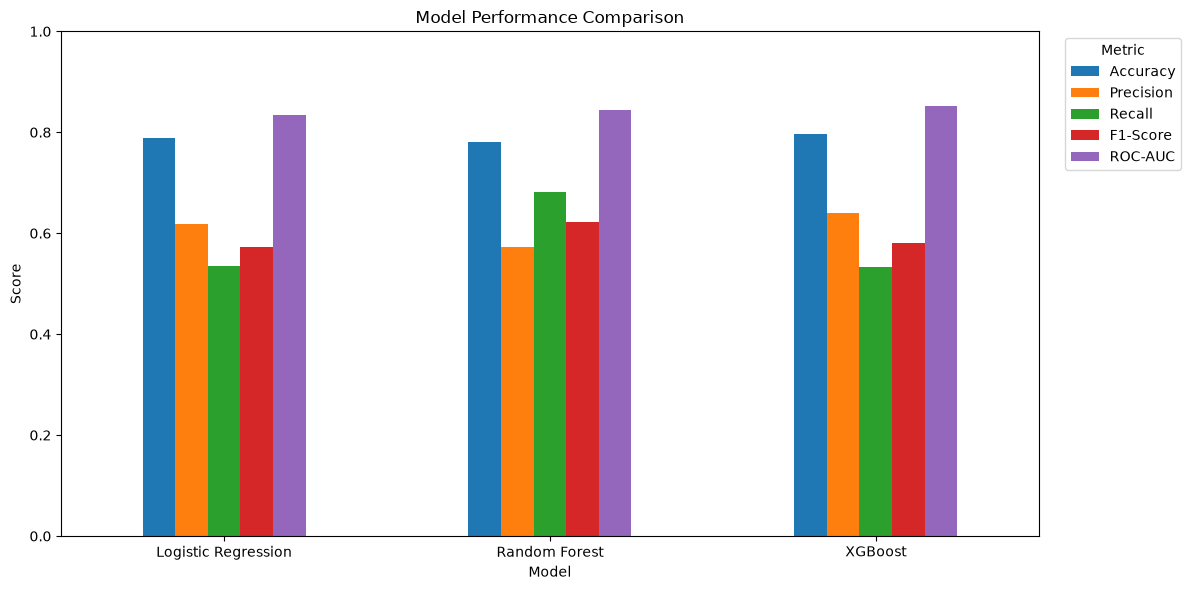

In [18]:
comparison_df.T.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### Overall Model Comparison

Three machine learning models were compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

XGBoost achieved the highest Accuracy (79.63%) and ROC-AUC (85.25%), indicating strong overall classification performance.

Random Forest achieved the highest Recall (68.18%) and F1-score (62.20%), making it more effective at identifying customers who are likely to churn.

Since identifying potential churn customers is a key objective, Random Forest is a promising candidate for further evaluation.

### Overall Model Comparison

Three machine learning models were compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

XGBoost achieved the highest Accuracy (79.63%) and ROC-AUC (85.25%), indicating strong overall classification performance.

Random Forest achieved the highest Recall (68.18%) and F1-score (62.20%), making it more effective at identifying customers who are likely to churn.

Since identifying potential churn customers is a key objective, Random Forest is a promising candidate for further evaluation.

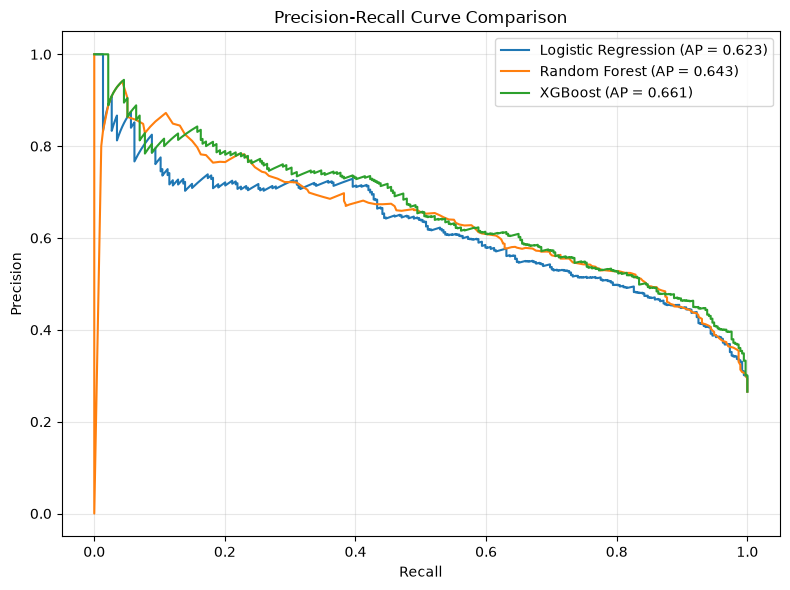

In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    precision_values, recall_values, _ = precision_recall_curve(
        y_test, probabilities
    )

    ap_score = average_precision_score(y_test, probabilities)

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {ap_score:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Classification Threshold Analysis

By default, classification models use a threshold of 0.5 to assign class labels.

However, changing this threshold can affect Precision and Recall.

In this section, we examine different thresholds to understand how they influence churn detection performance.

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]

threshold_results = []

for threshold in thresholds:
    predictions = (rf_pred_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.4837,0.8743,0.6229
1,0.35,0.5114,0.8369,0.6349
2,0.40,0.5299,0.7807,0.6314
3,0.45,0.5551,0.7273,0.6296
4,0.50,0.5702,0.6845,0.6221
5,0.55,0.5770,0.6310,0.6028
6,0.60,0.6128,0.5882,0.6003


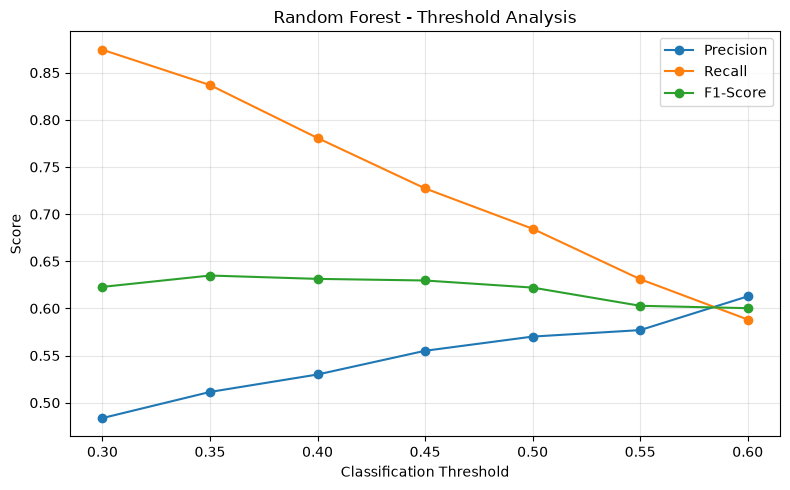

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision")
plt.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall")
plt.plot(threshold_df["Threshold"], threshold_df["F1-Score"], marker="o", label="F1-Score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest - Threshold Analysis")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Classification Threshold Analysis

The default classification threshold of 0.5 may not provide the best balance between Precision and Recall.

Different thresholds are evaluated to understand their impact on churn detection.

Lower thresholds generally increase Recall while potentially reducing Precision.

The final threshold should reflect the business objective and the cost of missed churn customers versus unnecessary retention interventions.

### Threshold Analysis

The Random Forest model was evaluated using classification thresholds ranging from 0.30 to 0.60.

A threshold of 0.35 achieved the highest F1-score of 0.6349, providing the best Precision-Recall balance among the tested thresholds.

A threshold of 0.30 achieved the highest Recall of 87.43%, but with lower Precision.

This demonstrates the trade-off between identifying more churn customers and generating additional false positive predictions.

The threshold of 0.35 is considered a candidate for further validation.

## 13. Validation-Based Threshold Selection

The test dataset should not be used to optimize the classification threshold.

We split the training data into training and validation subsets to select a suitable threshold.

The test dataset will be reserved for the final unbiased model evaluation.

In [22]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

Training subset: (4507, 24)
Validation set: (1127, 24)


In [23]:
rf_validation_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

rf_validation_model.fit(X_train_sub, y_train_sub)

val_probabilities = rf_validation_model.predict_proba(X_val)[:, 1]

In [24]:
validation_results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)

    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, val_predictions),
        "Recall": recall_score(y_val, val_predictions),
        "F1-Score": f1_score(y_val, val_predictions)
    })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(4))

,Threshold,Precision,Recall,F1-Score
0,0.30,0.4848,0.8562,0.6191
1,0.35,0.5258,0.8194,0.6405
2,0.40,0.5415,0.7860,0.6412
3,0.45,0.5707,0.7425,0.6453
4,0.50,0.5989,0.6990,0.6451
5,0.55,0.6274,0.6589,0.6427
6,0.60,0.6581,0.5987,0.6270


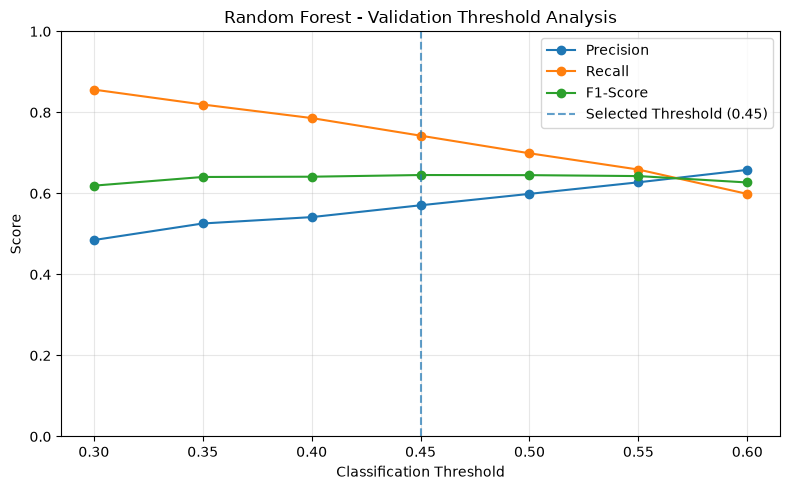

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    validation_df["Threshold"],
    validation_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    validation_df["Threshold"],
    validation_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    validation_df["Threshold"],
    validation_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    x=0.45,
    linestyle="--",
    alpha=0.7,
    label="Selected Threshold (0.45)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Random Forest - Validation Threshold Analysis")
plt.xticks(validation_df["Threshold"])
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Validation-Based Threshold Selection

The classification threshold was evaluated on a separate validation set to avoid optimizing it directly on the test set.

A threshold of 0.45 achieved the highest F1-score (0.6453), with a Recall of 74.25% and Precision of 57.07%.

This threshold was selected as a candidate because it provides a reasonable balance between identifying churn customers and limiting false positive predictions.

The final performance will be evaluated on the untouched test set.

In [26]:
final_rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

final_rf_model.fit(X_train, y_train)

final_test_probabilities = final_rf_model.predict_proba(X_test)[:, 1]

final_threshold = 0.45

final_test_predictions = (
    final_test_probabilities >= final_threshold
).astype(int)

In [27]:
final_results = {
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Precision": precision_score(y_test, final_test_predictions),
    "Recall": recall_score(y_test, final_test_predictions),
    "F1-Score": f1_score(y_test, final_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, final_test_probabilities)
}

display(
    pd.DataFrame(
        final_results.items(),
        columns=["Metric", "Score"]
    ).round(4)
)

,Metric,Score
0,Accuracy,0.7729
1,Precision,0.5551
2,Recall,0.7273
3,F1-Score,0.6296
4,ROC-AUC,0.8438


### Final Random Forest Model Evaluation

The final Random Forest model was trained on the complete training dataset and evaluated on the untouched test dataset using a classification threshold of 0.45.

The model achieved:

- Accuracy: 77.29%
- Precision: 55.51%
- Recall: 72.73%
- F1-score: 62.96%
- ROC-AUC: 84.38%

The model successfully identified approximately 73% of actual churn customers.

The results indicate that the selected threshold provides a balance between churn detection and false positive predictions.

## 14. Final Confusion Matrix

The confusion matrix evaluates the final Random Forest model using the selected classification threshold of 0.45.

It provides a detailed breakdown of correct and incorrect predictions on the test dataset.

In [28]:
final_cm = confusion_matrix(y_test, final_test_predictions)

display(pd.DataFrame(
    final_cm,
    index=["Actual No Churn", "Actual Churn"],
    columns=["Predicted No Churn", "Predicted Churn"]
))

,Predicted No Churn,Predicted Churn
Actual No Churn,817,218
Actual Churn,102,272


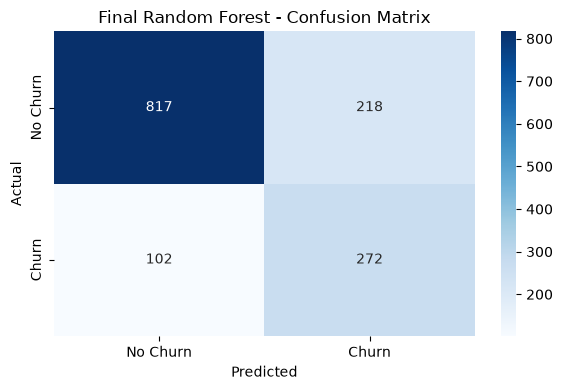

In [29]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [30]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "model": final_rf_model,
        "threshold": final_threshold
    },
    "../models/final_random_forest.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


### Final Confusion Matrix Analysis

The final Random Forest model correctly identified 272 churn customers and 817 non-churn customers.

It produced 218 false positive predictions and missed 102 actual churn customers.

Compared to the baseline Logistic Regression model, the final Random Forest model reduced the number of missed churn customers from 174 to 102.

This demonstrates an improvement in identifying customers at risk of churning.